# EMG Plots

1. **PSTH**: Peristimulus time histogram around rest events (bin_size: 25ms)
2. **Band Power**: Average band power distributions across recovery conditions (1/5/10 min)

In [38]:
import json
import os
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch

# Try kagglehub for data path, fallback to cache
try:
    import kagglehub
    data_path = Path(kagglehub.dataset_download("levshaazz/emg-muscle-recovery")) / "data"
except Exception:
    data_path = Path("/Users/shikaiyi/.cache/kagglehub/datasets/levshaazz/emg-muscle-recovery/versions/1/data")

SAMPLE_RATE = 1000  # Hz
BANDPASS_LOW = 20
BANDPASS_HIGH = 500
NOTCH_FREQ = 50
N_CHANNELS = 3

In [39]:
def load_and_preprocess(
    filepath: str,
    sfreq: int = SAMPLE_RATE,
    bandpass_low: int = BANDPASS_LOW,
    bandpass_high: int = BANDPASS_HIGH,
    notch_freq: int = NOTCH_FREQ,
) -> Tuple[np.ndarray, np.ndarray, Dict]:
    """Load EMG, apply baseline correction, bandpass and notch filters."""
    df = pd.read_csv(f"{filepath}.csv")
    time = df.iloc[:, 0].values
    data = df.iloc[:, 1:4].values.astype(float)
    if np.max(data) > 10:
        data = data * 3.3 / 65535

    with open(f"{filepath}_points.json", "r") as f:
        points = json.load(f)

    end_idx = np.searchsorted(time, 22.0)
    if end_idx >= len(time):
        end_idx = len(time)
    time = time[:end_idx]
    data = data[:end_idx, :]

    # Baseline correction
    baseline_end = points["baseline"]
    idx_baseline = np.searchsorted(time, baseline_end)
    idx_baseline = min(idx_baseline, len(time))
    if idx_baseline > 0:
        baseline_mean = np.mean(data[:idx_baseline, :], axis=0)
        data = data - baseline_mean

    # Bandpass filter
    nyq = sfreq / 2
    low, high = bandpass_low / nyq, min(bandpass_high / nyq, 0.99)
    b, a = butter(4, [low, high], btype="bandpass")
    for ch in range(N_CHANNELS):
        data[:, ch] = filtfilt(b, a, data[:, ch])

    # Notch filter
    b_notch, a_notch = iirnotch(notch_freq, 30.0, sfreq)
    for ch in range(N_CHANNELS):
        data[:, ch] = filtfilt(b_notch, a_notch, data[:, ch])

    return time, data, points

## 1. PSTH Plot

**Figure 1**: last 5s of sample1 + first 5s of sample2 (10s window, rest at t=5s)
**Figure 2**: last 5s of sample2 + first 5s of sample3 (10s window, rest at t=5s)

Each figure has 3 subplots: 1min rest, 5min rest, 10min rest.
Bin size: 25ms.

In [40]:
BIN_SIZE = 0.5
WINDOW_DUR = 5.0  # 5 seconds per segment
SEGMENT_DUR = 10.0  # 10s: last5s + first5s

# Collect PSTH by window type and rest condition
# psth_trials[window_key][rest_time] = list of (bin_centers, psth_vals)
# psth_per_user[user_id][window_key][rest_time] = (bin_centers, psth_vals)
psth_trials = {
    "last5s1_first5s2": {"1min": [], "5min": [], "10min": []},
    "last5s2_first5s3": {"1min": [], "5min": [], "10min": []},
}
psth_per_user = {}

for user_id in sorted(os.listdir(data_path)):
    user_path = data_path / user_id
    if not user_path.is_dir() or not user_id.isdigit():
        continue

    for rest_time in ["1min", "5min", "10min"]:
        rest_path = user_path / rest_time
        if not rest_path.exists():
            continue

        if not all((rest_path / f"exp_{e}.csv").exists() for e in [1, 2, 3]):
            continue

        try:
            _, data1, _ = load_and_preprocess(str(rest_path / "exp_1"))
            _, data2, _ = load_and_preprocess(str(rest_path / "exp_2"))
            _, data3, _ = load_and_preprocess(str(rest_path / "exp_3"))
        except Exception:
            continue

        n = int(WINDOW_DUR * SAMPLE_RATE)
        n_bins = int(SEGMENT_DUR / BIN_SIZE)
        bin_centers = np.arange(n_bins) * BIN_SIZE + BIN_SIZE / 2

        def compute_psth(seg_data):
            rect = np.mean(np.abs(seg_data), axis=1)  # mean rectified EMG across channels
            psth_vals = np.zeros(n_bins)
            for i in range(n_bins):
                idx_start = int(i * BIN_SIZE * SAMPLE_RATE)
                idx_end = min(int((i + 1) * BIN_SIZE * SAMPLE_RATE), len(rect))
                if idx_end > idx_start:
                    psth_vals[i] = np.mean(rect[idx_start:idx_end])
            return psth_vals

        # Window 1: last5s(s1) + first5s(s2)
        seg1 = np.vstack([data1[-n:, :], data2[:n, :]])
        psth1 = compute_psth(seg1)
        psth_trials["last5s1_first5s2"][rest_time].append((bin_centers, psth1))

        # Window 2: last5s(s2) + first5s(s3)
        seg2 = np.vstack([data2[-n:, :], data3[:n, :]])
        psth2 = compute_psth(seg2)
        psth_trials["last5s2_first5s3"][rest_time].append((bin_centers, psth2))

        # Per-user storage
        uid = int(user_id)
        if uid not in psth_per_user:
            psth_per_user[uid] = {"last5s1_first5s2": {}, "last5s2_first5s3": {}}
        psth_per_user[uid]["last5s1_first5s2"][rest_time] = (bin_centers, psth1)
        psth_per_user[uid]["last5s2_first5s3"][rest_time] = (bin_centers, psth2)

# Compute mean and SEM per condition (averaged across all subjects)
def avg_trials(trial_list):
    if not trial_list:
        return np.array([]), np.array([]), np.array([])
    t = trial_list[0][0]
    arr = np.array([p[1] for p in trial_list])
    return t, np.mean(arr, axis=0), np.std(arr, axis=0) / np.sqrt(len(arr))

psth_avg = {}
for wkey in psth_trials:
    psth_avg[wkey] = {}
    for rkey in psth_trials[wkey]:
        t, m, s = avg_trials(psth_trials[wkey][rkey])
        psth_avg[wkey][rkey] = (t, m, s)
        print(f"{wkey} {rkey}: {len(psth_trials[wkey][rkey])} trials")

last5s1_first5s2 1min: 12 trials
last5s1_first5s2 5min: 13 trials
last5s1_first5s2 10min: 14 trials
last5s2_first5s3 1min: 12 trials
last5s2_first5s3 5min: 13 trials
last5s2_first5s3 10min: 14 trials


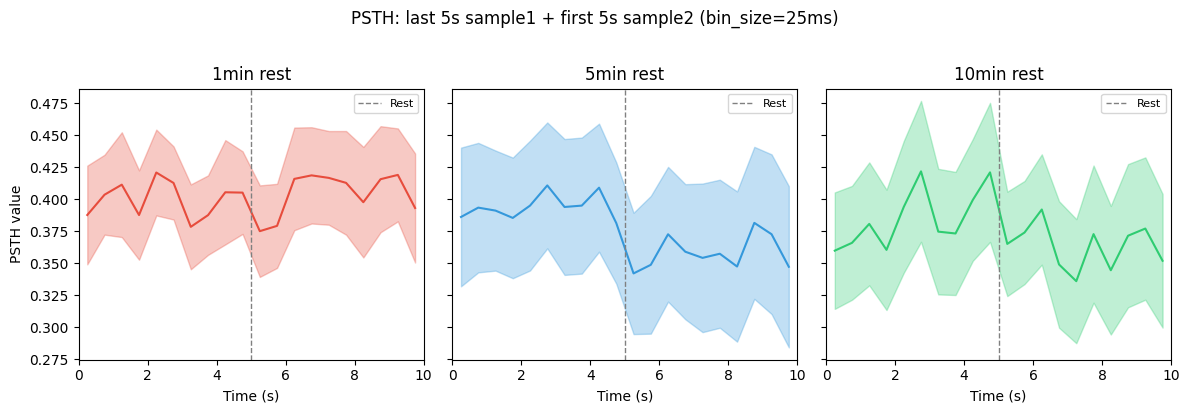

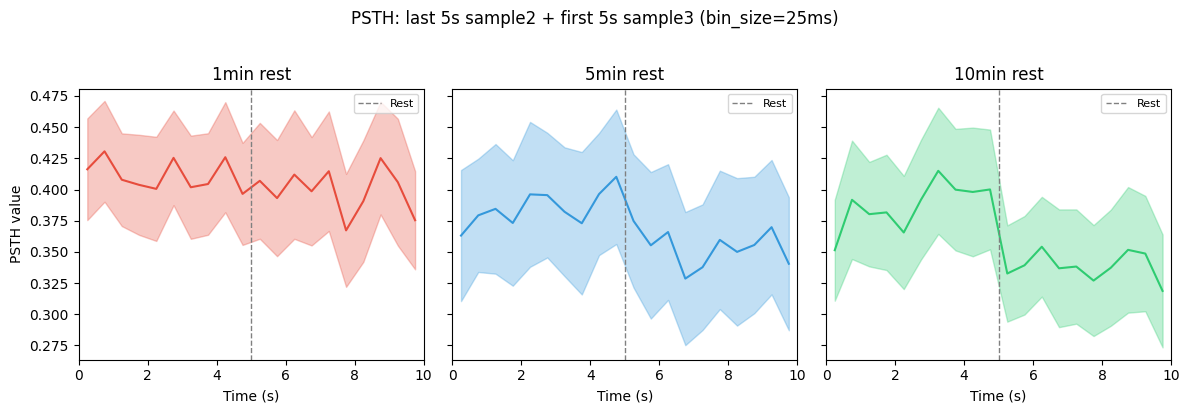

In [41]:
# Plot PSTH: two figures, each with 3 subplots (1min, 5min, 10min rest)
rest_labels = ["1min", "5min", "10min"]
colors = {"1min": "#e74c3c", "5min": "#3498db", "10min": "#2ecc71"}

for fig_idx, (wkey, title) in enumerate([
    ("last5s1_first5s2", "last 5s sample1 + first 5s sample2"),
    ("last5s2_first5s3", "last 5s sample2 + first 5s sample3"),
]):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
    fig.suptitle(f"PSTH: {title} (bin_size=25ms)", fontsize=12, y=1.02)

    for ax_idx, rkey in enumerate(rest_labels):
        ax = axes[ax_idx]
        t, m, s = psth_avg[wkey][rkey]
        if len(t) > 0:
            ax.plot(t, m, color=colors[rkey], linewidth=1.5)
            ax.fill_between(t, m - s, m + s, alpha=0.3, color=colors[rkey])
        ax.axvline(x=5, color="gray", linestyle="--", linewidth=1, label="Rest")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("PSTH value" if ax_idx == 0 else "")
        ax.set_title(f"{rkey} rest")
        ax.set_xlim(0, 10)
        ax.legend(loc="upper right", fontsize=8)

    plt.tight_layout()
    plt.show()

### PSTH Subject-specific (user_id 1–14)

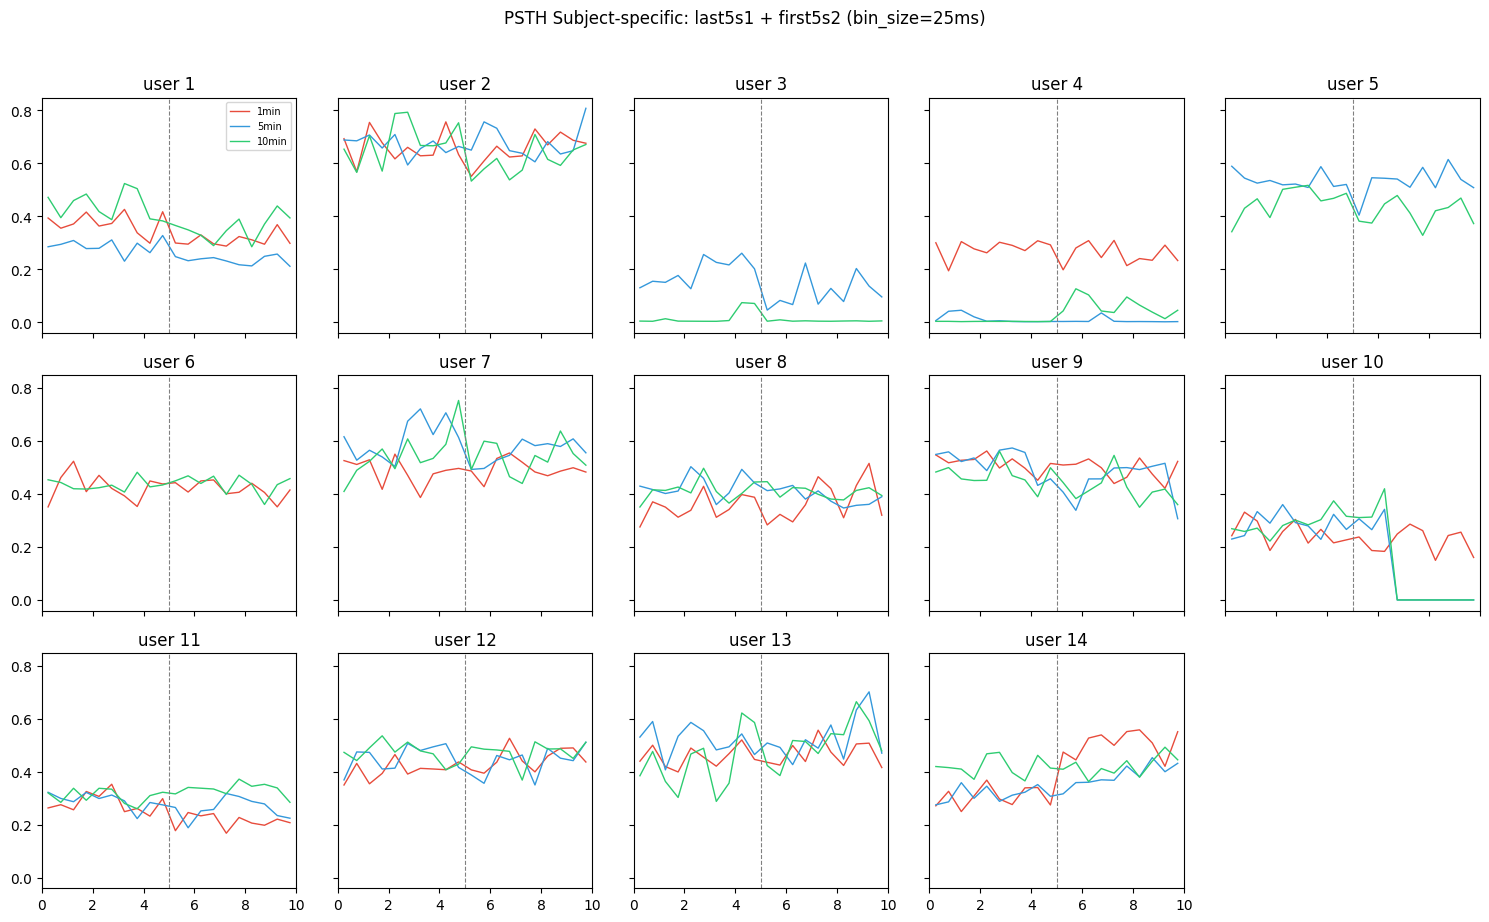

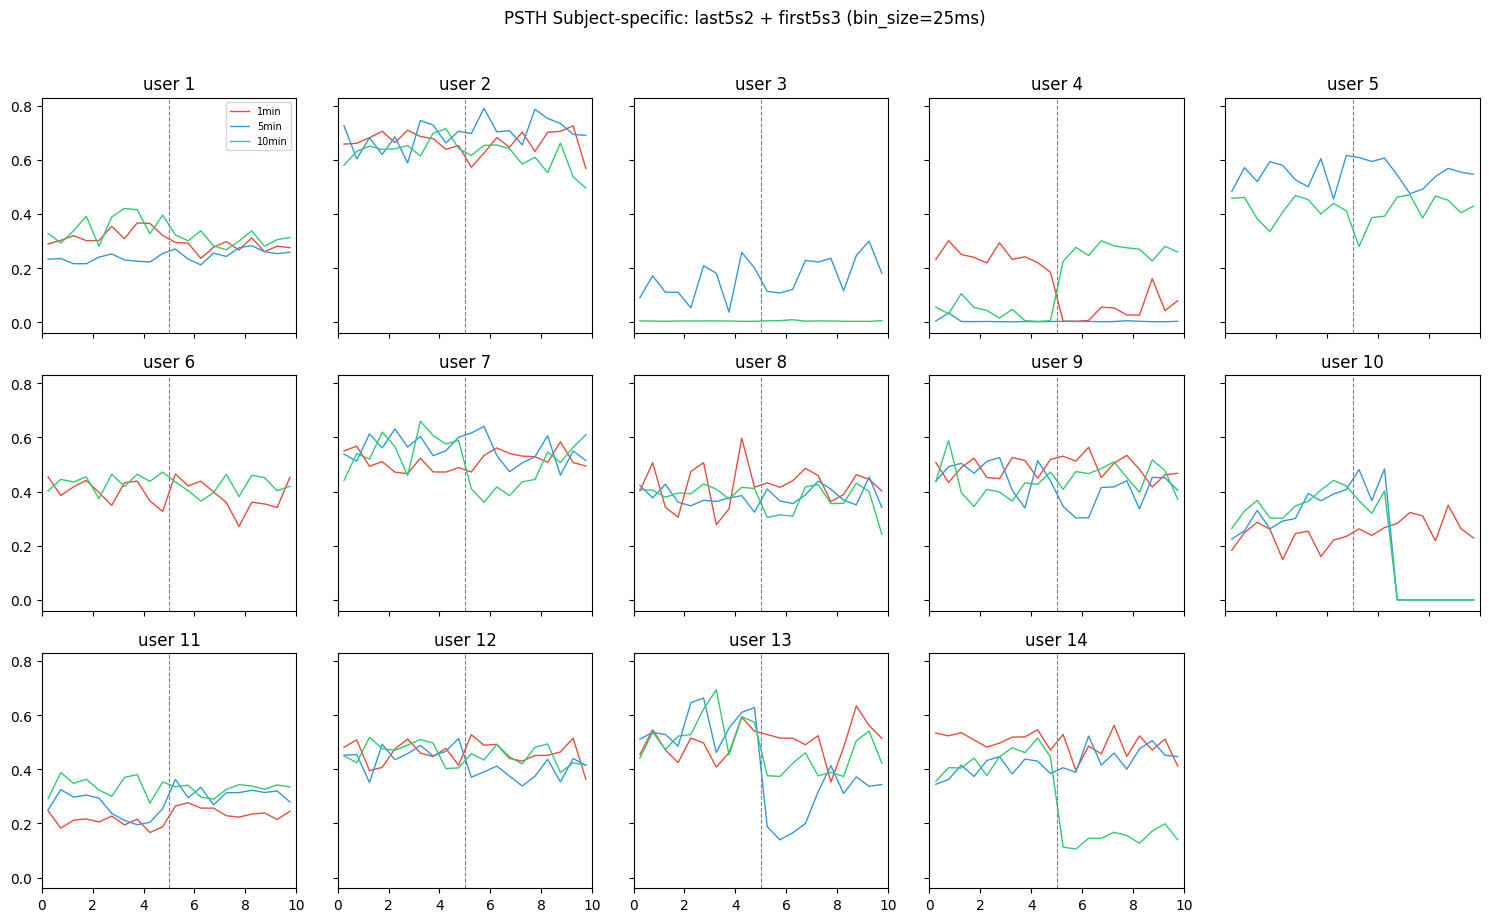

In [42]:
# PSTH subject-specific: all 14 users in one big figure, 5 per row, 3 rows
rest_labels = ["1min", "5min", "10min"]
colors = {"1min": "#e74c3c", "5min": "#3498db", "10min": "#2ecc71"}
n_cols, n_rows = 5, 3
user_ids = sorted(psth_per_user.keys())

for wkey, title in [("last5s1_first5s2", "last5s1 + first5s2"), ("last5s2_first5s3", "last5s2 + first5s3")]:
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 9), sharex=True, sharey=True)
    fig.suptitle(f"PSTH Subject-specific: {title} (bin_size=25ms)", fontsize=12, y=1.02)
    axes_flat = axes.flatten()
    for idx, uid in enumerate(user_ids):
        ax = axes_flat[idx]
        if uid in psth_per_user and wkey in psth_per_user[uid]:
            for rkey in rest_labels:
                if rkey in psth_per_user[uid][wkey]:
                    t, m = psth_per_user[uid][wkey][rkey]
                    ax.plot(t, m, color=colors[rkey], linewidth=1, label=rkey)
        ax.axvline(x=5, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"user {uid}")
        ax.set_xlim(0, 10)
    for idx in range(len(user_ids), n_cols * n_rows):
        axes_flat[idx].set_visible(False)
    axes_flat[0].legend(loc="upper right", fontsize=7)
    plt.tight_layout()
    plt.show()

## 2. Average Band Power Distributions

x-axis: frequency bands, y-axis: mean band power, grouped by recovery condition (1/5/10 min).

In [43]:
# Load band power data (run preprocessing.ipynb first if needed)
BAND_PATH = "dataset_filtered_bands.csv"
BAND_LABELS = ["1-4", "5-8", "9-16", "17-32", "33-64", "65-128", "129-256"]  # Hz (matches preprocessing)

if not Path(BAND_PATH).exists():
    raise FileNotFoundError(f"Run preprocessing.ipynb first to generate {BAND_PATH}")

df_bands = pd.read_csv(BAND_PATH)

# Average across channels for each band, then mean per rest condition
band_cols_agg = []
for b in range(1, 8):
    cols = [f"ch_{ch}_band_{b}" for ch in [1, 2, 3]]
    band_cols_agg.append(df_bands[cols].mean(axis=1))
df_band_agg = pd.DataFrame(np.column_stack(band_cols_agg), columns=BAND_LABELS)
df_band_agg["rest_int"] = df_bands["rest_int"].values
df_band_agg["user_id"] = df_bands["user_id"].values

# Mean band power per rest condition (1/5/10 min)
rest_labels = {0: "1 min", 1: "5 min", 2: "10 min"}
mean_by_rest = {}
for r in [0, 1, 2]:
    mask = df_band_agg["rest_int"] == r
    mean_by_rest[rest_labels[r]] = df_band_agg.loc[mask, BAND_LABELS].mean().values

# Per-user band power: mean_by_rest_per_user[user_id][rest_label] = array
mean_by_rest_per_user = {}
for uid in df_band_agg["user_id"].unique():
    df_u = df_band_agg[df_band_agg["user_id"] == uid]
    mean_by_rest_per_user[uid] = {}
    for r in [0, 1, 2]:
        mask = df_u["rest_int"] == r
        if mask.any():
            mean_by_rest_per_user[uid][rest_labels[r]] = df_u.loc[mask, BAND_LABELS].mean().values

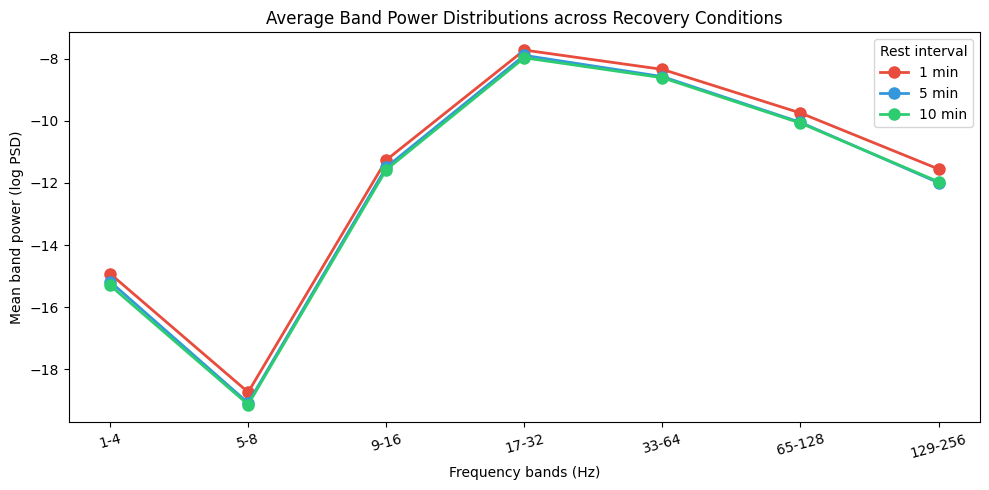

In [44]:
# Plot: Line chart
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#e74c3c", "#3498db", "#2ecc71"]  # 1min, 5min, 10min
for i, (label, vals) in enumerate(mean_by_rest.items()):
    ax.plot(BAND_LABELS, vals, "o-", color=colors[i], linewidth=2, markersize=8, label=label)
ax.set_xlabel("Frequency bands (Hz)")
ax.set_ylabel("Mean band power (log PSD)")
ax.set_title("Average Band Power Distributions across Recovery Conditions")
ax.legend(title="Rest interval")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Band Power Subject-specific (user_id 1–14)

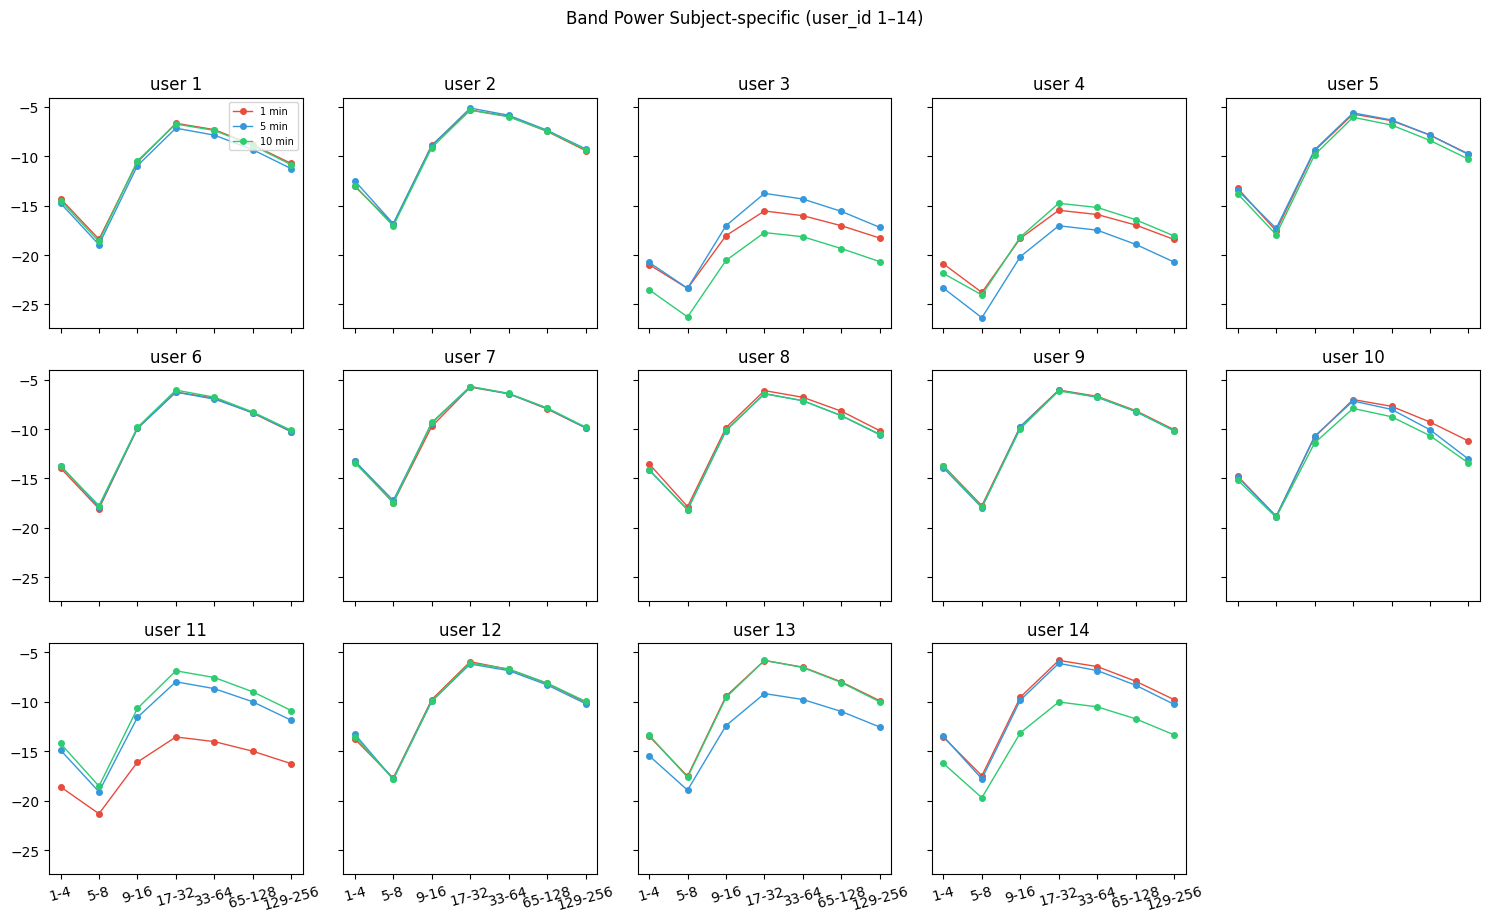

In [45]:
# Band power subject-specific: all 14 users in one big figure, 5 per row, 3 rows (line chart)
line_colors = ["#e74c3c", "#3498db", "#2ecc71"]
n_cols, n_rows = 5, 3
user_ids = sorted(mean_by_rest_per_user.keys())
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 9), sharex=True, sharey=True)
fig.suptitle("Band Power Subject-specific (user_id 1–14)", fontsize=12, y=1.02)
axes_flat = axes.flatten()
for idx, uid in enumerate(user_ids):
    ax = axes_flat[idx]
    if uid in mean_by_rest_per_user:
        for i, (label, vals) in enumerate(mean_by_rest_per_user[uid].items()):
            ax.plot(BAND_LABELS, vals, "o-", color=line_colors[i], linewidth=1, markersize=4, label=label)
    ax.set_title(f"user {uid}")
    ax.tick_params(axis="x", rotation=15)
for idx in range(len(user_ids), n_cols * n_rows):
    axes_flat[idx].set_visible(False)
axes_flat[0].legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()